# Reliability with Monte-Carlo simulation 
*Fabian Nütz*

This document briefly outlines the core concepts, ideas and motivations as well as the development process and design decisions behind pandaict's Monte Carlo simulation for reliability calculation.

## Introduction
As introduced in *Reliability metrics and analytic calculation*, analytic reliability calculation in pandaICT is rather rudimentary and limited. It can only yield correct results in special cases where the network routing and topology would fit the set of assumptions made beforehand. Such the goal was to implement a universal tool or algorithm with converges reasonably fast toward the true reliability of any given network. However, no closed analytical expression exists which sufficiently approximates the reliability for any given network, a numerical algorithm is required. One way to approach such a problem would be to enumerate the state space, meaning that for all possible states a given network could be in, one would determine its functionality and from this *state space enumeration* could in theory derive the probabilistic quantities of interest. The problem with such an approach is that since any given network with $n$ components that have two states each can assume $2^n$ possible states, such an algorithm would always necessarily scale exponentially with the size of the network, which would mark it unsuitable for the problem at hand.
Instead, the approach taken here is based on Monte Carlo simulation, a class of algorithms which estimate deterministic quantities through repeated random sampling. Rather than exhaustively enumerating all $2^n$ possible states, the algorithm samples random trajectories through the state space by simulating the stochastic evolution of the network over time. Each component $i$ is modelled as an independent two-state continuous-time Markov process, alternating between an operational (UP) and a failed (DOWN) state, where the time to failure and the time to repair are each drawn from exponential distributions with rates $\lambda_i$ and $\mu_i$, respectively. Due to the memoryless property of the exponential distribution, the next event across all components is itself exponentially distributed with a rate equal to the sum of all individual transition rates $r_i \in \{\lambda_i, \mu_i\}$, and the identity of the transitioning component can be sampled proportionally to its rate. By repeatedly simulating such event-driven trajectories each time recording the elapsed time until the network loses (or regains) connectivity between designated source–target pairs the algorithm collects independent samples of the system's time to failure and time to repair. The quantities of interest, such as the Mean Time to Failure (MTTF) and Mean Time to Repair (MTTR), are then obtained as simple arithmetic means over these samples, which by the Law of Large Numbers converge to the true expected values as the number of simulations $N \rightarrow \infty$. Crucially, the computational cost of this approach scales linearly with the number of samples $N$ and polynomially with the size of the network (rather than exponentially), making it applicable to networks of arbitrary size and topology at the expense of a statistical estimation error that decreases as $\mathcal{O}(1/\sqrt{N})$.

## Introducing the model
To specify the simulation model precisely, consider a network with $n=|E|+|V|$ stochastic components, where $E$ is a set of edges and $N$ a set of nodes, each of which resides in one of two states: operational (UP) or failed (DOWN). The dynamics of each component $i$ is governed by two parameters: a failure rate $\lambda_i>0$ and a repair rate $\mu_i \geq 0 $. When component $i$ is in the UP state, the time until its next failure follows an exponential distribution with rate $\lambda_i$, that is
$T_i^{fail} ∼ \exp(\lambda_i)$, whose probability density is $f(t) = \lambda_i e^{-\lambda_i t}$ for $t \geq 0$, yielding a mean time between failures of $1/\lambda_i$. Likewise, when component $i$ is in the DOWN state, the time until its repair follows $T_i^{repair} ∼ \exp(\mu_i)$ with a mean time to repair of $1/\mu_i$. For non-repairable components, $\mu_i = 0$ and the component remains permanently unavailable once in the DOWN state. The instantaneous transition rate of component $i$ at any given moment is therefore state-dependent:

$$
r_i = \begin{cases}
    \lambda_i & \text{if component } i \text{ is UP,} \\
    \mu_i     & \text{if component } i \text{ is DOWN.}
\end{cases}
$$

Since all component processes are mutually independent, the well-known competing exponentials property implies that the time until the next event anywhere in the network is itself exponentially distributed, with rate equal to the sum of all current individual transition rates:

$$
\Delta t \sim \exp(R), ~~ R = \sum_i r_i
$$

The identity of the component undergoing this transition follows a discrete distribution in which each component $j$ is selected with probability proportional to its share of the total rate:

$$
P(\text{component j transitions next}) = \frac{r_j}{R}.
$$

After the selected component $j$ changes state from UP to DOWN or vice versa its rate is updated from $\lambda_j$ to $\mu_j$ (or conversly), and the total rate $R$ is adjusted accordingly. The network is considered operational if the set of currently functioning components supports connectivity between designated source–target node pairs according to a functionality constraint detailed below. Each simulated trajectory thus proceeds event by event — alternating between sampling an inter-event time from $\exp(R)$ and drawing the transitioning component from the rate-weighted distribution until the system's connectivity state changes. The accumulated elapsed time at that point is recorded as one sample of the time to failure (if the system transitioned from operational to failed) or one sample of the time to repair (if from failed to operational). For repairable systems, the simulation does not reset the component states after each repair; instead, it chains `depth` consecutive failure–repair cycles within a single run, so that only the first cycle begins from a fully operational network while subsequent cycles inherit the component states from the preceding repair phase, thereby reducing the initialisation bias that would arise from always starting in a pristine state.

As described earlier for repairable systems, the simulation is governed by two distinct parameters: the number of independent runs $N$ and the number of chained failure–repair cycles $d$ (referred to as `depth`) within each run. These two parameters serve complementary purposes and cannot, in general, be collapsed into one. If only $N$ were used with $d=1$, every run would begin from a fully operational network in which all components are in the UP state, introducing a systematic upward bias in the MTTF estimate — the algorithm would never observe failures originating from partially degraded configurations that arise naturally during sustained operation. Conversely, if only $d$ were made large with $N=1$, the successive cycles within the single run would form a Markov chain whose samples are autocorrelated, since each cycle inherits the component states of the preceding one. While such a chain is ergodic for fully repairable systems and therefore converges to the correct expectation in the limit $d\rightarrow \infty$, its effective sample size $N_{eff}$ is strictly smaller than the nominal count $d$, making naive variance estimates unreliable. Moreover, the entire workload would execute on a single processor core, forfeiting the parallelisation speedup entirely. The present design therefore uses a moderate $N$ to ensure statistical independence and parallelisability, combined with a moderate $d>1$ to allow each run's internal chain to move away from the pristine initial state before contributing samples. Within each run, the $d$ cycle-level results are averaged into a single per-run estimate; the final MTTF and MTTR are then computed as the arithmetic mean over the $N$ per-run averages, whose mutual independence guarantees that standard errors and confidence intervals can be obtained from the sample variance across runs without further correction.

## The algorithm in a nutshell
The efficient realisation of this simulation scheme requires several carefully chosen data structures and algorithmic techniques, which shall be briefly introduced here before being discussed in detail. Since the core event loop must be executed a very large number of times across all $N$ samples, the entire simulation engine is compiled to native machine code using Numba's just-in-time (JIT) compilation framework, which necessitates that all data be represented as plain NumPy arrays rather than high-level Python objects (e.g. pandas DataFrames). The network topology is accordingly converted from its original graph representation into a compressed sparse row (CSR) format. This CSR-format consists of three integer arrays encoding adjacency offsets, neighbour indices, and edge indices, which permits cache-efficient traversal of the network structure. Within each simulated event, two operations govern the computational cost. The first is the selection of the next transitioning component, which requires drawing a sample from a discrete distribution weighted by the individual transition rates of all $n=∣V∣+∣E∣$ components. A naive implementation would accumulate the rate distribution by linearly scanning all components in  $\mathcal{O}(n)$ time; instead, the algorithm employs a Fenwick tree (also known as a Binary Indexed Tree), a data structure that maintains prefix sums over the rate array and supports both weighted random selection and point updates in  $\mathcal{O}(\log(n))$ time. When a component changes state, only its own entry in the Fenwick tree needs to be updated, which is a local $\mathcal{O}(\log(n))$ operation, rather than rebuilding the entire cumulative distribution. The second operation is the evaluation of system connectivity, which determines whether the network still fulfills its functionality constraint after a component has changed state. This is performed by a stack-based depth-first search (DFS) operating directly on the CSR arrays, visiting each active node and traversing each active edge at most once in $\mathcal{O}(|V|+|E|)$ time. The overall per-event computational cost is therefore dominated by the connectivity check at $\mathcal{O}(|V|+|E|)$, with the Fenwick tree contributing a lower-order $\mathcal{O}(\log(|V|+|E|))$ term for event sampling and rate maintenance. These per-event costs establish the foundation upon which the following performance considerations (parallelisation, lazy evaluation, and the critical component analysis) are built.

## Parallelization and computational complexity
A key property of Monte Carlo simulation in this context is that each sample i.e., each simulated trajectory through the state space, is statistically independent of all others. This renders the workload trivially parallel: the $N$ simulation runs can be distributed across $P$ processor cores with no inter-thread communication or synchronisation overhead. In the present implementation this is realised through Numba's just-in-time compiled parallel loops (`prange`), wherein each thread receives its own copy of the Fenwick tree and component state arrays and independently simulates complete failure–repair trajectories. The resulting wall-clock time scales approximately as $\mathcal{O}(N/P)$, yielding near-linear speedup with the number of available cores. Combined with the fact that the per-event computational cost is dominated by the $\mathcal{O}(V+E)$ depth-first search for connectivity and the $\mathcal{O}(\log(V+E)$ Fenwick tree operations for event sampling. Theoretically the overall algorithm scales polynomially, rather than exponentially, with the size of the network, making it applicable to systems of practical relevance. In quite a few cases where we actually measured the time complexity empirically there was convincing evidence of linear scaling with the size of the network in almost all cases. Here are some results:

## Binary Tree type networks
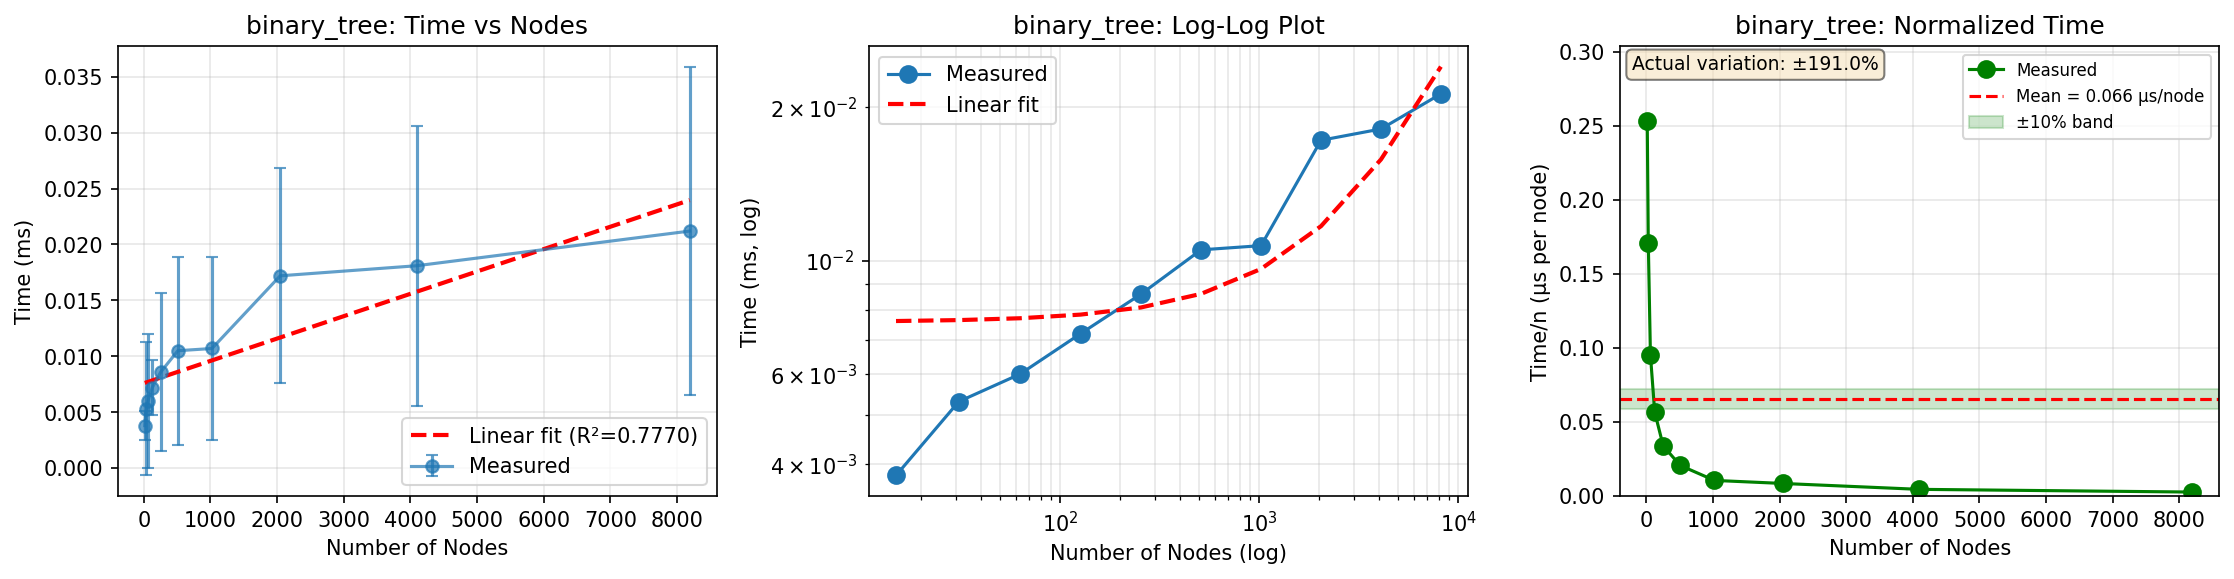

## Grid type networks
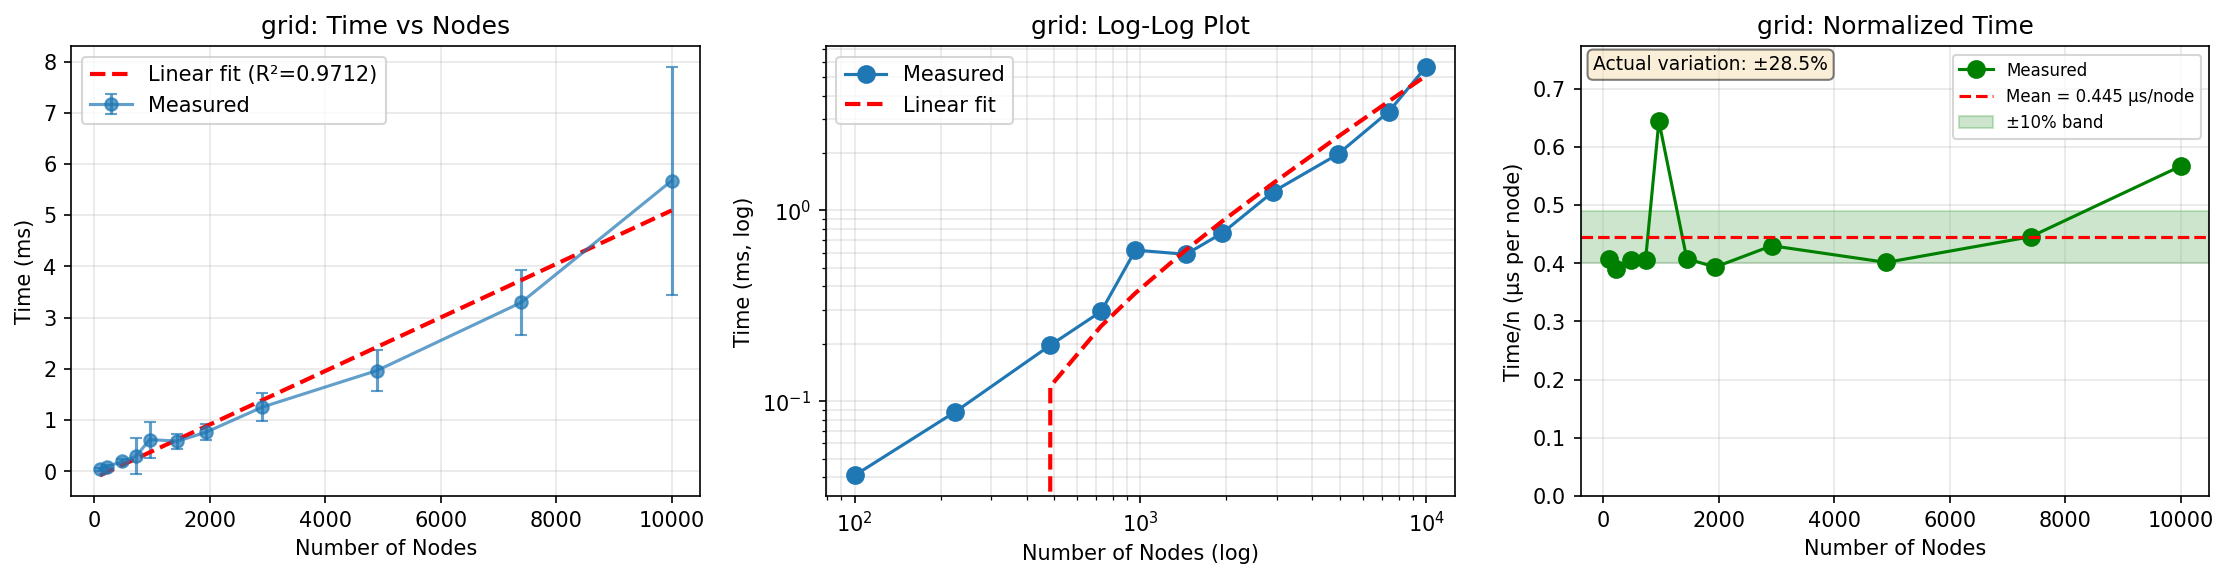

## Ladder type networks
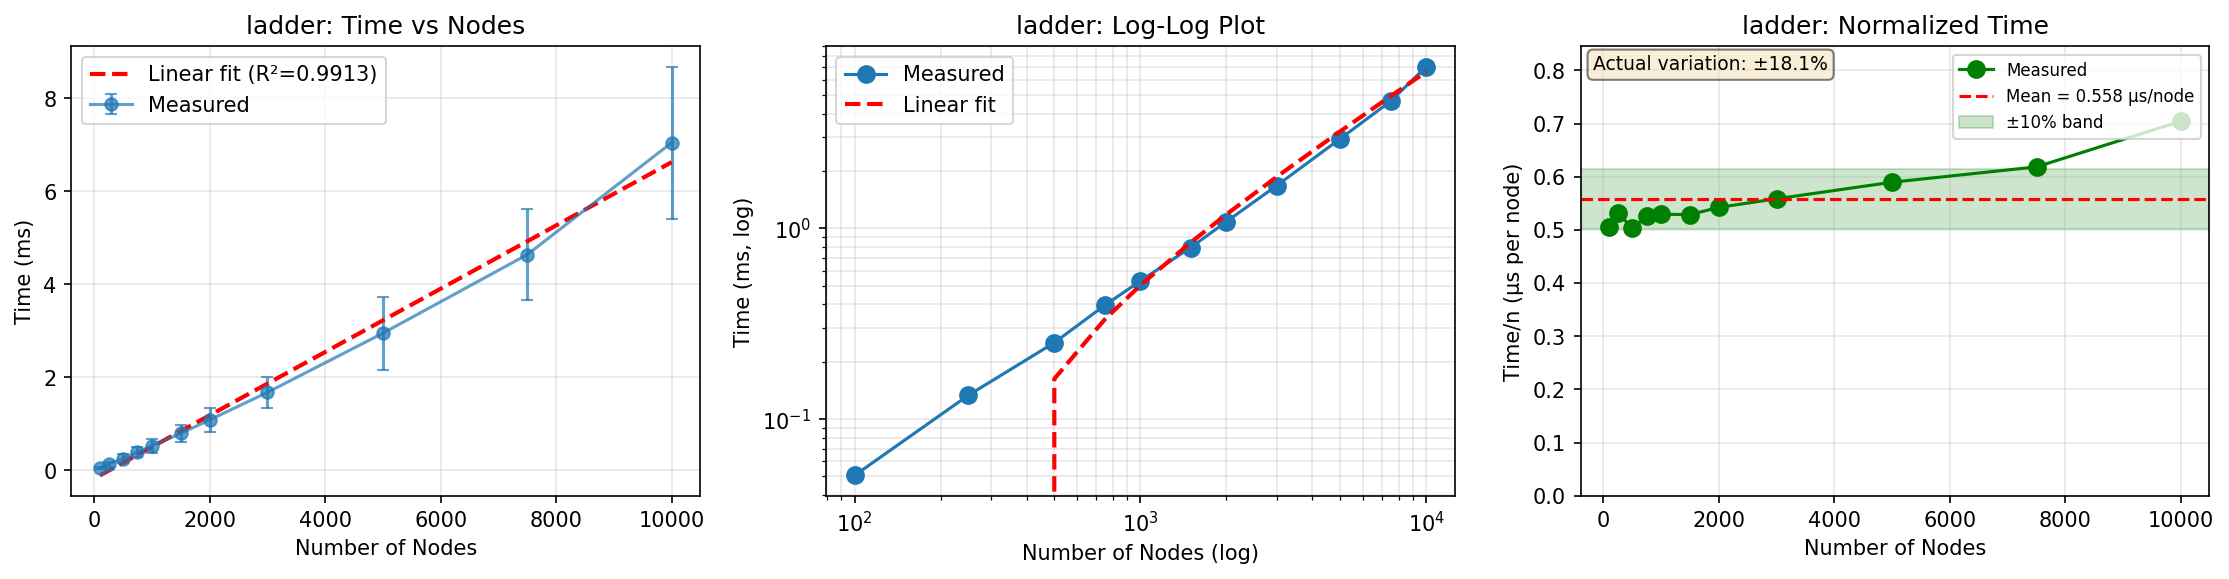

## Path type networks
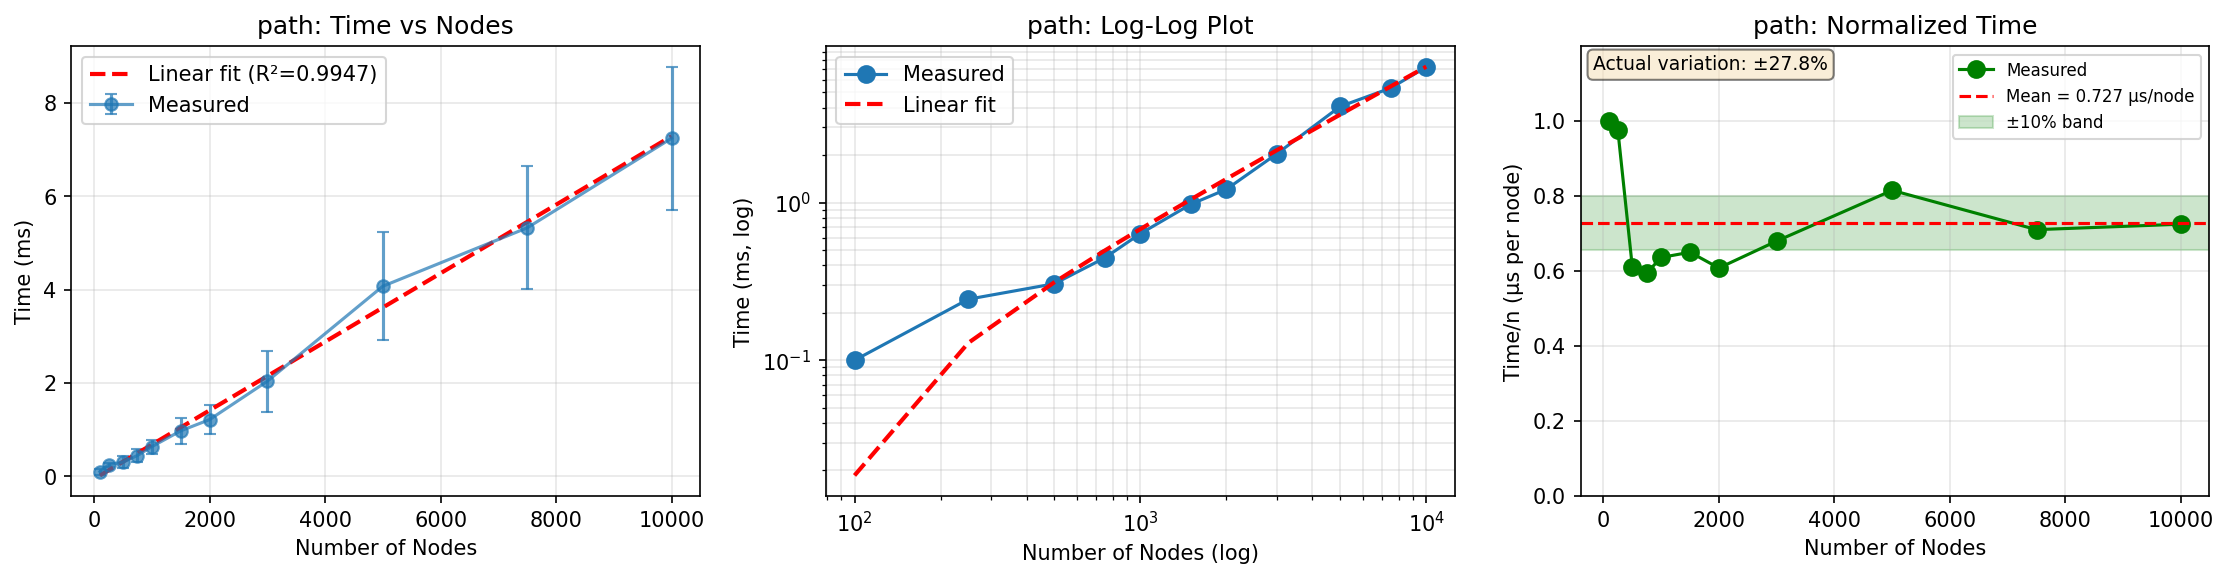

## Laziness
As discussed above the most expensive operation within each simulated event is the depth-first search that determines whether the network remains connected after a component transition. In many practical scenarios, particularly for highly reliable networks, a large number of component-level events may occur before the system-level connectivity state actually changes. Performing a full graph traversal after every single event is therefore wasteful in such cases. To address this, the algorithm introduces a tunable laziness parameter $l \in [0,1)$, which defers the connectivity check until at least $l \cdot (V+E)$ events have accumulated since the last check. One could interpret $l$ as the fraction of the network that has to change until we check the connectivity again. Between checks, the algorithm continues to sample and apply events at minimal cost, recording candidate critical components in a provisional buffer. Once the deferred check is performed, the buffer is either confirmed, if a system-level transition has indeed occurred, or discarded. This amortisation scheme reduces the average number of DFS calls per simulated transition by a factor roughly proportional to the event threshold, at the expense of a slight coarsening in the temporal resolution of the recorded transition times. For most practical reliability metrics such as the MTTF or MTTR, this trade-off is negligible, while the performance gain can be substantial for large or highly reliable networks.

## Functionality constraint
Beyond simple single-source, single-target connectivity, the algorithm supports an arbitrary number of source–target pairs $(s_1, t_1), ..., (s_m, t_m)$ together with a flexible functionality constraint governed by a parameter `min_connected`$\in \{1, ..., m\}$. The system is considered operational if and only if at least `min_connected` of the $m$ designated pairs are connected through functioning components. This generalisation subsumes several classical reliability models as special cases: setting `min_connected` $=m$ yields a series-type (*logical* **AND**) requirement in which all pairs must be simultaneously connected, setting `min_connected` $=1$ yields a parallel-type (*logical* **OR**) requirement in which any single connected pair suffices, and intermediate values realise $k$-out-of-$m$ redundancy schemes. Internally, early-exit logic is employed during the pair-wise connectivity evaluation: as soon as sufficiently many pairs have been confirmed connected the check returns immediately, and conversely, if the number of remaining unchecked pairs can no longer satisfy the threshold the check terminates early with a negative result. This allows the modelling of complex, application-specific functionality constraints, such as partial network degradation or redundant supply paths, without any modification to the core simulation logic.

## Last-Straw critical-component analysis

Finally, `analyze_critical_components_for_conn()` provides an integrated critical-component analysis that identifies which components are disproportionately associated with system-level failures. During the event-based simulation, the algorithm records the component whose state transition changes the system from operational to failed. For repairable systems, the component whose repair restores the system is recorded separately. Because this information is obtained directly from the existing event loop, the analysis requires only minor additional bookkeeping and no separate simulation campaign for each component.

For a non-repairable coherent system, the resulting proportion of system failures attributed to component $j$,

$$
\hat{p}_j^{\mathrm{attr}}
=
\frac{f_j}{\sum_i f_i},
$$

corresponds to an empirical Monte Carlo estimate of the Barlow–Proschan importance: the probability that component $j$ is the one whose failure causes the system to fail. In repairable systems, failures and restorations can occur repeatedly. The same attribution principle is therefore used as a recurrent, Barlow–Proschan-like measure for failure and restoration events rather than as the classical Barlow–Proschan importance.

By default, the attributed proportion is additionally normalized using a rate-based reference. This rate-based reference can be, in the case of failure events, interpreted as strictly serial reference network. In such a system the first component failure causes system failure and the probability that component $j$ fails first is

$$
p_j^{\mathrm{series}}= \frac{\lambda_j}{\sum_i \lambda_i},
$$

and hence is proportional to its normalized rate. For component $j$, the Criticality Score is

$$
C_j
=
\frac{\hat{p}_j^{\mathrm{attr}}}
     {\hat{p}_j^{\mathrm{ref}}}
=
\frac{f_j/\sum_i f_i}
     {r_j/\sum_i r_i},
$$

where $r_j$ denotes the component failure rate when analysing system failures and the repair rate when analysing system restorations. The reference proportion $r_j/\sum_i r_i$ represents how frequently the component would be expected to appear based on its nominal transition rate alone.

The normalized score therefore compares the observed proportion of system failures attributed to a component in the actual network under inspection with the corresponding attribution probability in the series based reference system.

A score of $C_j \approx 1$ indicates that the component is attributed approximately as many system-level transitions as expected from the rate-based reference. Values above $1$ indicate overrepresentation, while values below $1$ indicate underrepresentation. A high score therefore suggests that the component's role in the network makes its transitions particularly consequential relative to its nominal rate. However, the score should not be interpreted as a purely topological measure, since the rate-based reference does not fully account for state-dependent component exposure or the network states visited during the simulation.

This event-attribution approach differs from sensitivity measures such as Birnbaum importance, which quantify how changes in component reliability affect system reliability. A straightforward simulation-based estimate of such sensitivities generally requires additional simulations with perturbed component parameters. The present analysis instead extracts attribution information from the same simulations used to estimate system-level reliability metrics. Its marginal computational cost is therefore limited to recording and aggregating the relevant component events.

Exact attribution to a single component requires `laziness=0`. If `laziness>0`, several component events may occur between two connectivity checks, and intermediate changes in system state may remain undetected. In that case, the recorded components are candidates associated with the final inspection interval rather than exact causes of the observed system transition.

If `rate_adjustment=False`, the rate-based reference is omitted. In the current implementation, the attributed proportions are rescaled so that their mean over the components observed as causes is $1$. The returned values are therefore not raw attribution proportions, although their relative ranking is preserved.

## Sources and Literature

Birolini, A. (2017). Reliability engineering: Theory and practice (8th ed.). Springer.

Gertsbakh, I. B., & Shpungin, Y. (2010). Models of network reliability: Analysis, combinatorics, and Monte Carlo. CRC Press. https://doi.org/10.1201/b12536

Colbourn, C. J., & Harms, D. D. (1988). Bounding all-terminal reliability in computer networks. Networks, 18(1), 1–12. https://doi.org/10.1002/net.3230180102

Barlow, R. E., & Proschan, F. (1975). Importance of system components and fault tree events. *Stochastic Processes and Their Applications, 3*(2), 153–173. https://doi.org/10.1016/0304-4149(75)90013-7

Birnbaum, Z. W. (1969). On the importance of different components in a multicomponent system. In P. R. Krishnaiah (Ed.), *Multivariate Analysis II* (pp. 581-592). Academic Press.

https://de.wikipedia.org/wiki/Gelman-Rubin-Statistik

https://de.wikipedia.org/wiki/MCMC-Verfahren
